# Import libraries

In [24]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Load the data

## Load the EdGap data set

In [28]:
# Here, we read the school ID as an object because it is an identifier, not a numerical measurement.
edgap = pd.read_excel('/Users/linhchung/Desktop/Education/EdGap_data.xlsx',
                     dtype = {'NCESSCH School ID': object})

/opt/anaconda3/lib/python3.12/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


## Load the school information data

In [31]:
# We specify the encoding here so Python can correctly read the characters in this CSV file.
school_information = pd.read_csv('/Users/linhchung/Desktop/Education/ccd_sch_029_1617_w_la_11212017.csv',
                                encoding = 'unicode_escape')

/var/folders/cd/xsmvfhtx6c7cj7lgwtzkq0gm0000gp/T/ipykernel_23365/3660314500.py:2: DtypeWarning: Columns (6,9,14,15,18,19,21,22,25,26,29,31,35,39,41,42) have mixed types. Specify dtype option on import or set low_memory=False.
  school_information = pd.read_csv('/Users/linhchung/Desktop/Education/ccd_sch_029_1617_w_la_11212017.csv',


# Explore the contents of the data sets

## Start by looking at the head of each data frame.
This will let us see the names of the columns and a few example values for each column. We can also check whether the data is in tidy format.

In [33]:
edgap.head()

,NCESSCH School ID,CT Unemployment Rate,CT Pct Adults with College Degree,CT Pct Childre In Married Couple Family,CT Median Household Income,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [35]:
school_information.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,...,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported


In [37]:
pd.set_option('display.max_columns', None)
school_information.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,ST_SCHID,NCESSCH,SCHID,MSTREET1,MSTREET2,MSTREET3,MCITY,MSTATE,MZIP,MZIP4,LSTREET1,LSTREET2,LSTREET3,LCITY,LSTATE,LZIP,LZIP4,PHONE,WEBSITE,SY_STATUS,SY_STATUS_TEXT,UPDATED_STATUS,UPDATED_STATUS_TEXT,EFFECTIVE_DATE,SCH_TYPE_TEXT,SCH_TYPE,RECON_STATUS,OUT_OF_STATE_FLAG,CHARTER_TEXT,CHARTAUTH1,CHARTAUTHN1,CHARTAUTH2,CHARTAUTHN2,NOGRADES,G_PK_OFFERED,G_KG_OFFERED,G_1_OFFERED,G_2_OFFERED,G_3_OFFERED,G_4_OFFERED,G_5_OFFERED,G_6_OFFERED,G_7_OFFERED,G_8_OFFERED,G_9_OFFERED,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0020,1.000020e+10,100277.0,P O Box 9486,NaN,NaN,Birmingham,AL,35220,NaN,1000 Industrial School Road,NaN,NaN,Birmingham,AL,35220,NaN,(205)680-8574,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0050,1.000020e+10,101667.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,1601 County Rd. 57,NaN,NaN,Prattville,AL,36067,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0060,1.000020e+10,101670.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,2109 Bashi Rd Bldg 509,NaN,NaN,Thomasville,AL,36784,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0030,1.000020e+10,101705.0,P O Box 66,NaN,NaN,Mount Meigs,AL,36057,NaN,1000 Industrial School Road,NaN,NaN,Mount Meigs,AL,36057,NaN,(334)215-6039,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0040,1.000020e+10,101706.0,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,(205)838-4981,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported


## Use the info method to check the data types, size of the data frame, and numbers of missing values

In [41]:
edgap.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   object 
 1   CT Unemployment Rate                             7972 non-null   float64
 2   CT Pct Adults with College Degree                7973 non-null   float64
 3   CT Pct Childre In Married Couple Family          7961 non-null   float64
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   float64
dtypes: float64(6), object(1)
memory usage: 436.9+ KB


In [8]:
school_information.info()

<class 'pandas.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 65 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   SCHOOL_YEAR          102183 non-null  str    
 1   FIPST                102183 non-null  int64  
 2   STATENAME            102183 non-null  str    
 3   ST                   102183 non-null  str    
 4   SCH_NAME             102183 non-null  str    
 5   LEA_NAME             102183 non-null  str    
 6   STATE_AGENCY_NO      102183 non-null  object 
 7   UNION                2533 non-null    float64
 8   ST_LEAID             102183 non-null  str    
 9   LEAID                102183 non-null  object 
 10  ST_SCHID             102183 non-null  str    
 11  NCESSCH              102181 non-null  float64
 12  SCHID                102181 non-null  float64
 13  MSTREET1             102181 non-null  str    
 14  MSTREET2             1825 non-null    str    
 15  MSTREET3             28 non-

## Summary
1. The school information data set is much larger than the EdGap data set. Clearly the EdGap data set doesn not icnlude all schools.
2. There are missing values in each data set.
3. Each data set is in a tidy, or long format.
4. The data types for the variables of interest look correct, but the school identifier is an object in the EdGap data set and a float64 in the school information data set.

# Are the data suitable for answering the question?

We want to perform quick exploratory data anaysis to determine whether the data are sufficient to answer our question. If the data are not sufficient, we do not want to waste time doing anything that will not be productive.

## Make a pair plot to explore relationships between the variables.

<function matplotlib.pyplot.show(close=None, block=None)>

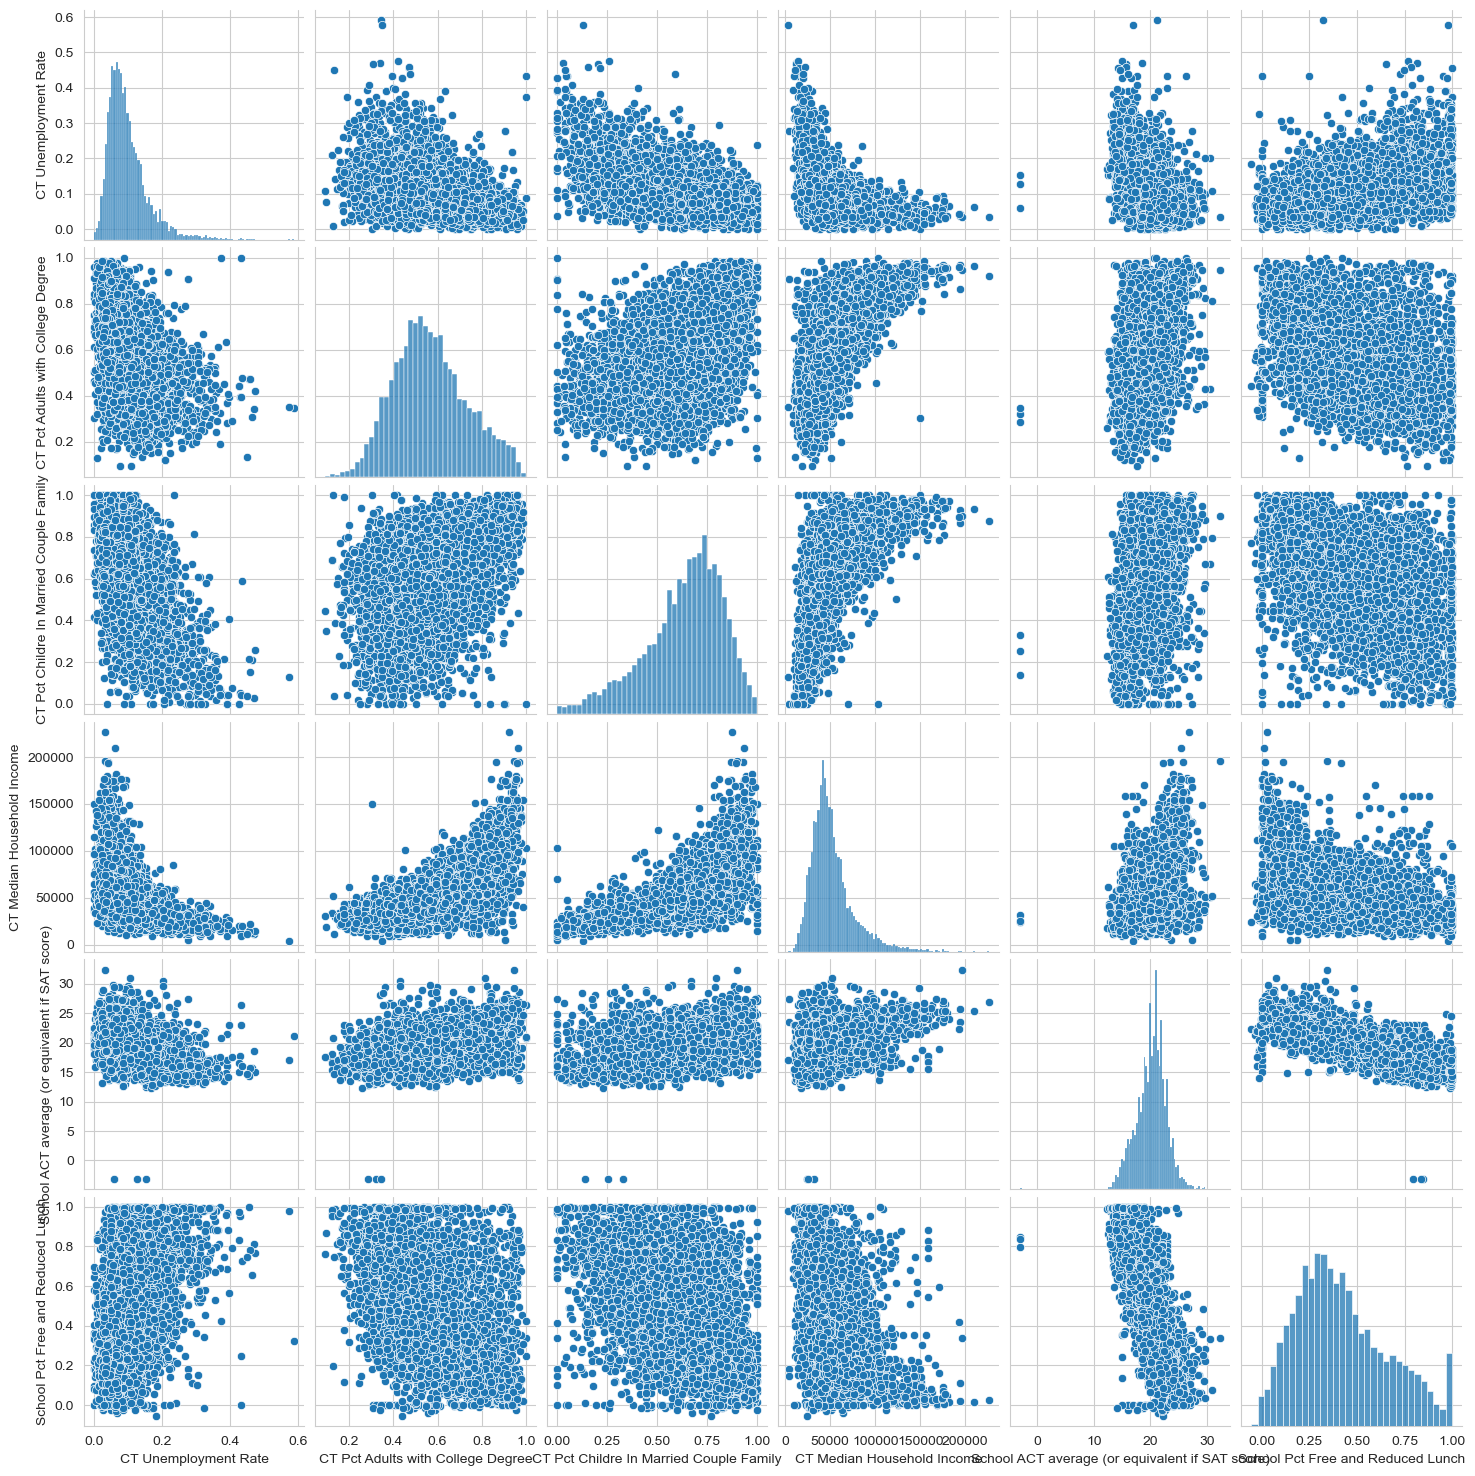

In [43]:
sns.pairplot(edgap.drop(columns='NCESSCH School ID'))
plt.show

## Add regression lines and format the pair plot

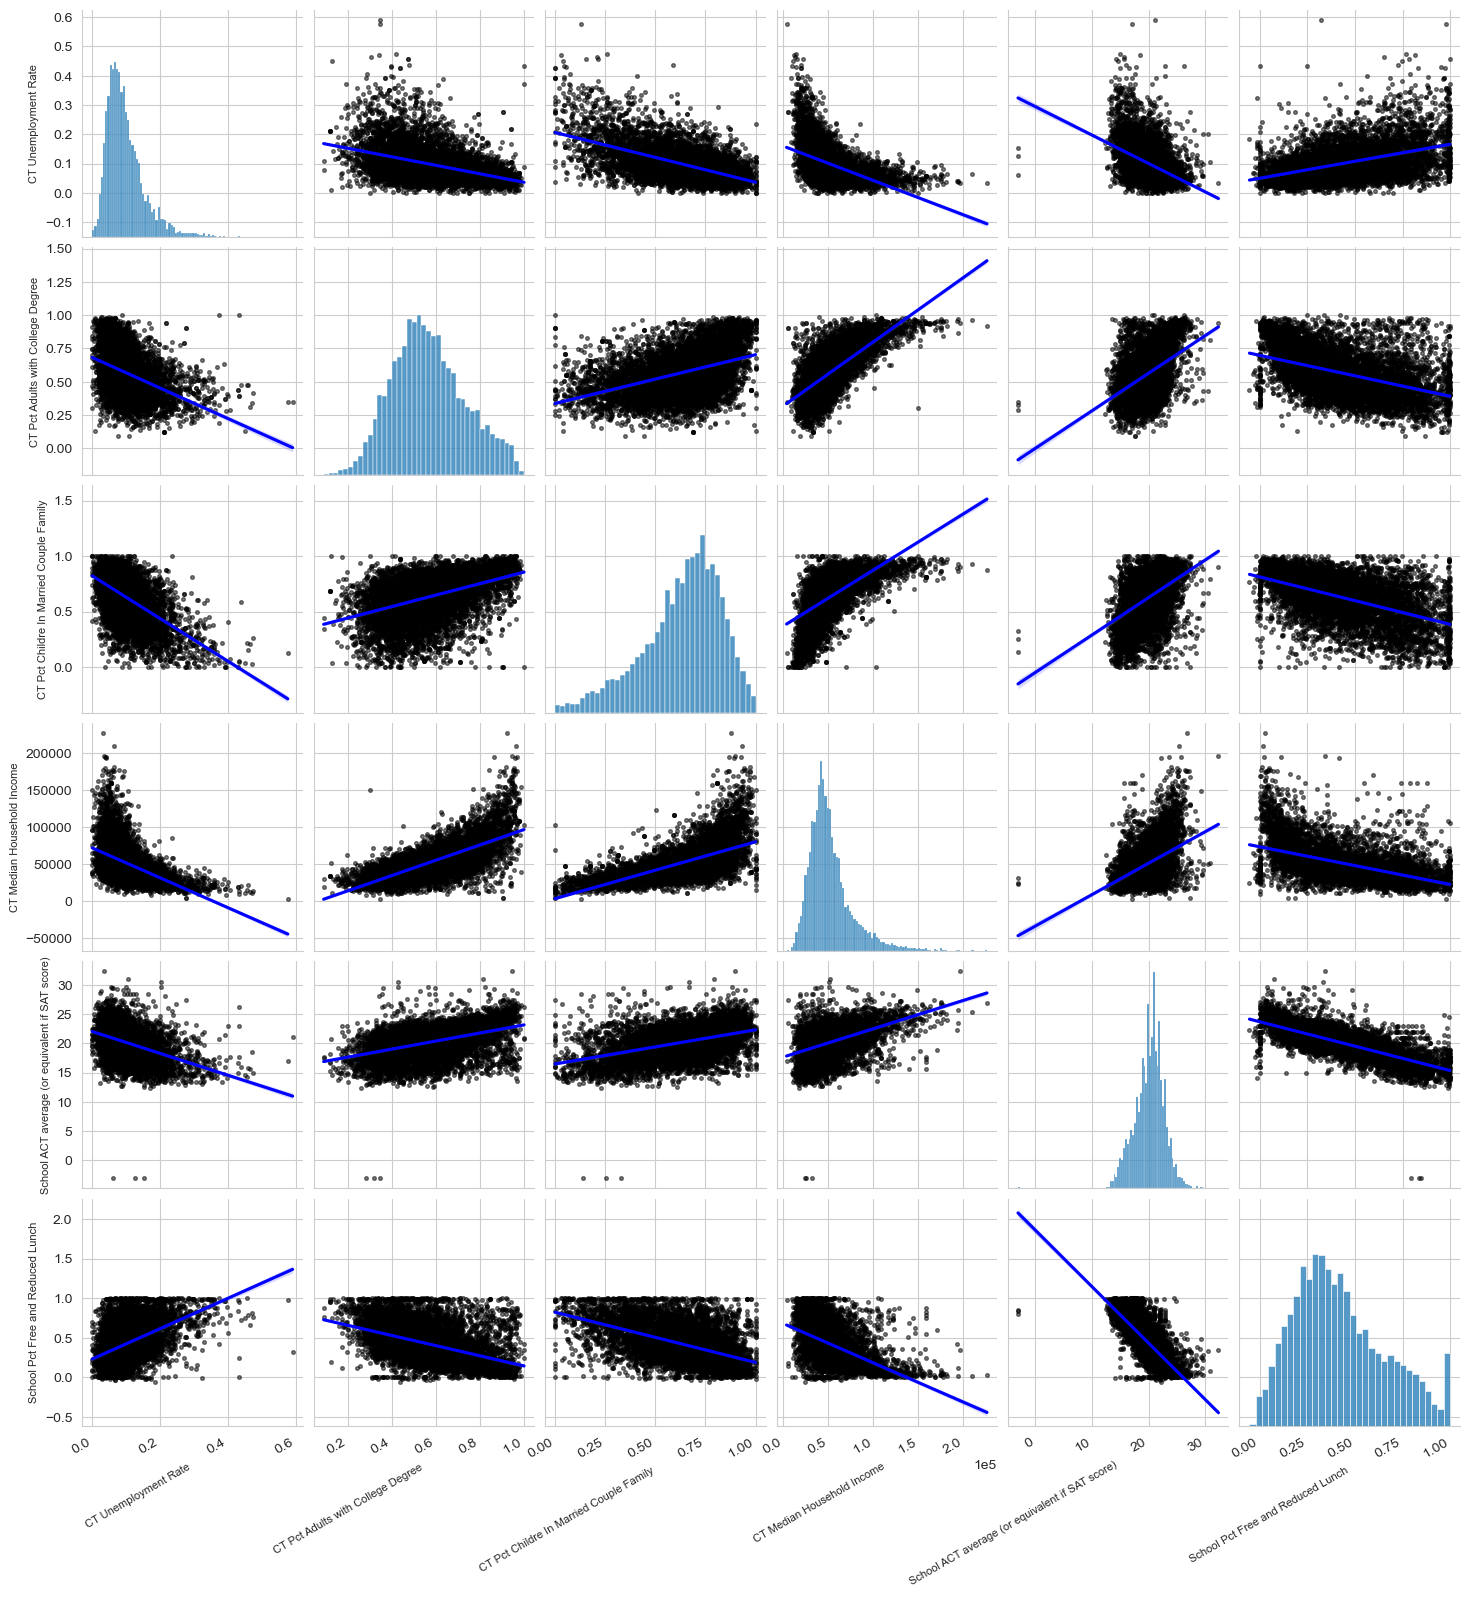

In [45]:
fig = sns.pairplot(
    edgap.drop(columns='NCESSCH School ID'),
    kind = 'reg', # Add regression line
    plot_kws = {
        'line_kws':{'color': 'blue'}, # Features related to lines
        'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7} # Feature related to the scatter plots
    }
)

# Further adjust the axis formatting
for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
       ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8) # Y-axis label size

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

### Plot a single row 

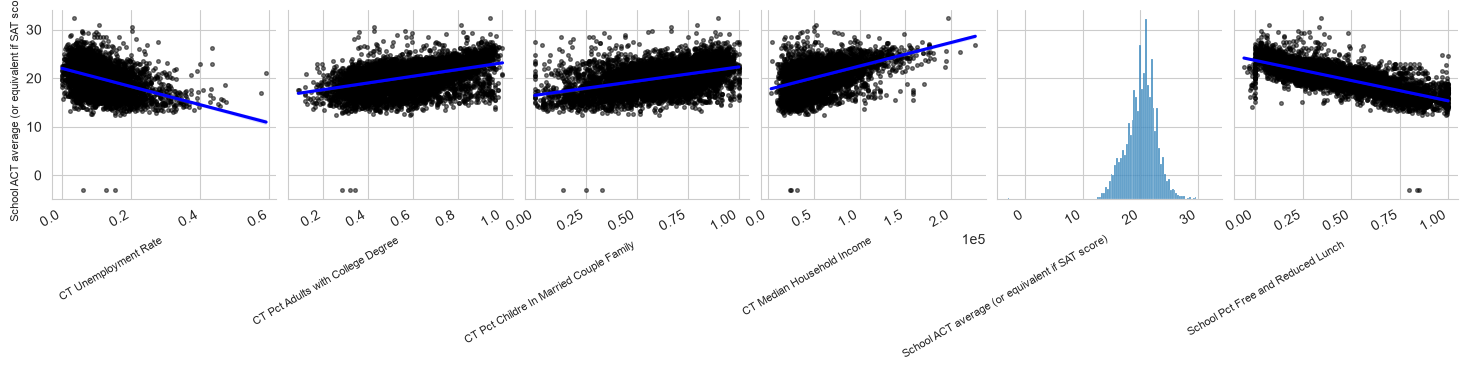

In [11]:
fig = sns.pairplot(
    edgap.drop(columns='NCESSCH School ID'),
    y_vars = ['School ACT average (or equivalent if SAT score)'],
    kind = 'reg', # Add regression line
    plot_kws = {
        'line_kws':{'color': 'blue'}, # Features related to lines
        'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7} # Feature related to the scatter plots
    }
)

# Further adjust the axis formatting
for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
       ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8) # Y-axis label size

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

## Summary
1. There appears to be a relationship between the socioeconomic variables and the ACT score.
2. There are some out-of-range ACT and percent lunch values that will nneed to be dealt with.
3. We should have confidence that it is worthwhile to spend time preparing the data for analysis.

# Data Preparation

## Select revevant subsets of the data

The school information data set contains many columns. We only need the year, school identity, location, and school type information.

Keep the columns SCHOOL_YEAR, NCESSCH, LSTATE, LZIP, SCH_TYPE_TEXT, LEVEL, CHARTER_TEXT

In [47]:
school_information = school_information[
    ['SCHOOL_YEAR', 'NCESSCH', 'LSTATE', 'LZIP', 'SCH_TYPE_TEXT', 'LEVEL', 'CHARTER_TEXT']
]

In [49]:
school_information.head()

,SCHOOL_YEAR,NCESSCH,LSTATE,LZIP,SCH_TYPE_TEXT,LEVEL,CHARTER_TEXT
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


### Rename columns

We will rename the columns to follow best practices of style and being informative. We can do this before or after joining the data sets. We will do it before joining the data sets to make it obvious that they key has the same name in each data set (this isn't required, but it makes your work easier to read).

In [51]:
edgap.columns

Index(['NCESSCH School ID', 'CT Unemployment Rate',
       'CT Pct Adults with College Degree',
       'CT Pct Childre In Married Couple Family', 'CT Median Household Income',
       'School ACT average (or equivalent if SAT score)',
       'School Pct Free and Reduced Lunch'],
      dtype='object')

In [53]:
edgap = edgap.rename(
    columns = {
       'NCESSCH School ID': 'id', 
       'CT Unemployment Rate': 'rate_unemployment',
       'CT Pct Adults with College Degree': 'percent_college',
       'CT Pct Childre In Married Couple Family': 'percent_married', 
       'CT Median Household Income': 'median_income',
       'School ACT average (or equivalent if SAT score)': 'average_act',
       'School Pct Free and Reduced Lunch': 'percent_lunch',
    }
)

In [55]:
edgap.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [57]:
school_information.columns

Index(['SCHOOL_YEAR', 'NCESSCH', 'LSTATE', 'LZIP', 'SCH_TYPE_TEXT', 'LEVEL',
       'CHARTER_TEXT'],
      dtype='object')

In [59]:
school_information = school_information.rename(
    columns = {
       'NCESSCH': 'id', 
       'SCHOOL_YEAR': 'year',
       'LSTATE': 'state',
       'LZIP': 'zip_code', 
       'SCH_TYPE_TEXT': 'school_type',
       'LEVEL': 'school_level',
       'CHARTER_TEXT': 'charter',
    }
)

In [19]:
school_information.head()

,year,id,state,zip_code,school_type,school_level,charter
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


### Summary
1. We selected a subset of columns of the school information data set.
2. We renamed the columns for clarity and to follow formatting guidelines.
3. We are ready to join the data frames.

## Join data frames

We want to join the DataFrames using the identity of the school as the key. The identity is given by the NCESSCH school identity. The value is an object in the EdGap data set and a float64 in the school information data set.

We will cast the id column in the school_information DataFrame as an object.

In [61]:
school_information['id'] = school_information['id'].astype('object')

In [65]:
school_information.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   year          102183 non-null  object
 1   id            102181 non-null  object
 2   state         102183 non-null  object
 3   zip_code      102183 non-null  object
 4   school_type   102181 non-null  object
 5   school_level  102179 non-null  object
 6   charter       102179 non-null  object
dtypes: object(7)
memory usage: 5.5+ MB


### Join the data frames and call the result df.

In [68]:
df = edgap.merge(
    school_information,
    how = 'left', # use the left join
    on = 'id'     # use id as the key
)

In [70]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No


In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7986 non-null   object 
 1   rate_unemployment  7972 non-null   float64
 2   percent_college    7973 non-null   float64
 3   percent_married    7961 non-null   float64
 4   median_income      7966 non-null   float64
 5   average_act        7986 non-null   float64
 6   percent_lunch      7986 non-null   float64
 7   year               7898 non-null   object 
 8   state              7898 non-null   object 
 9   zip_code           7898 non-null   object 
 10  school_type        7898 non-null   object 
 11  school_level       7898 non-null   object 
 12  charter            7898 non-null   object 
dtypes: float64(6), object(7)
memory usage: 811.2+ KB


### Summary
1. We joined the data sets using the school id as the key.
2. We first cast the id as an object to have the same data type for the key in each data set.
3. We used a left join to keep all EgGap data.

## Quality Control

### Check the min and max values in each column.
There are natural bounds for some numerical variables in the data set. 

We can use the describe method to compute descriptive statistics.

In [74]:
df.describe()

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
count,7972.000000,7973.000000,7961.000000,7966.000000,7986.000000,7986.000000
mean,0.098730,0.568930,0.633440,52026.905222,20.181532,0.420651
std,0.058959,0.165704,0.196764,24228.057079,2.595201,0.239754
min,0.000000,0.091493,0.000000,3589.000000,-3.070818,-0.054545
25%,0.058655,0.450828,0.523810,36597.250000,18.600000,0.238501
50%,0.085649,0.554979,0.667594,46833.500000,20.400000,0.381570
75%,0.123376,0.676571,0.777135,61369.250000,21.910867,0.575447
max,0.590278,1.000000,1.000000,226181.000000,32.362637,0.998729


We can also use min and max.

In [77]:
df.select_dtypes(include = ['number']).agg(['min', 'max']).round(2)

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
min,0.00,0.09,0.0,3589.0,-3.07,-0.05
max,0.59,1.00,1.0,226181.0,32.36,1.00


### Set out-of-range values to NaN using np.nan

In [80]:
df.loc[df['percent_lunch'] < 0, 'percent_lunch'] = np.nan

In [82]:
df.loc[df['average_act'] < 1, 'average_act'] = np.nan

### Check the types, levels, and charter status of schools

In [85]:
df['school_type'].value_counts()

school_type
Regular School                 7885
Alternative School               10
Special Education School          2
Career and Technical School       1
Name: count, dtype: int64

In [87]:
df['school_level'].value_counts()

school_level
High            7230
Other            631
Not reported      35
Elementary         2
Name: count, dtype: int64

In [89]:
df['charter'].value_counts()

charter
No                7329
Yes                352
Not applicable     217
Name: count, dtype: int64

### Keep only high schools.

In [92]:
df = df.loc[df['school_level'] == 'High'] 

### Check for any duplicated rows

In [95]:
df.duplicated().sum()

0

It's still possible that there are incorrectly recorded values in the data set, but we will not go that far in this example

### Identify missing values

How many values of each variable are missing?

In [97]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,3
percent_lunch,20
year,0
state,0
zip_code,0


### What states do we have data from?

In [99]:
df['state'].value_counts()

state
TX    913
OH    654
IL    564
PA    543
MI    498
NC    407
FL    404
GA    367
WI    351
NJ    341
MO    337
IN    321
NY    295
TN    265
WA    263
MA    253
KY    198
LA    194
WY     38
DE     24
Name: count, dtype: int64

In [101]:
df['state'].nunique()

20

### Plot results on a map

In [104]:
import plotly.offline as po
import plotly.graph_objs as pg

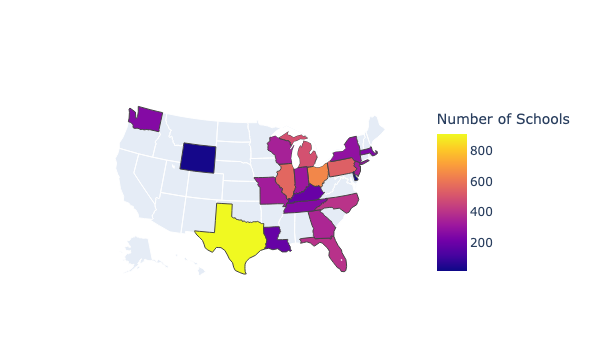

In [106]:
layout = dict(
    geo = {"scope": "usa"}, coloraxis_colorbar = dict(title = "Number of Schools")
)

data = dict(
    type = "choropleth",
    locations = df["state"].value_counts().index,
    locationmode = "USA-states",
    z = df["state"].value_counts().values,
    coloraxis = "coloraxis",
)

x = pg.Figure(data = [data], layout = layout)

po.iplot(x)

We are missing a large amount of USA data due to omission. This is not evident by examining NaA values in the data set. We could obtain this information from public records, but we will not do that here.

### Drop the rows where the average ACT score is missing.

ACT score is the reponse variable of our interest and the percentage of missing values for ACT score is low.

In [111]:
df = df.dropna(subset = ['average_act'])

In [113]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,0
percent_lunch,20
year,0
state,0
zip_code,0


If we drop rows that have NaNs for any socioeconomic variables, then we will negatively affect our analysis. We don't want to drop the entire row just because one socioeconomic variable is missing, because we would also lose the useful information that is available in the other variables. We will impute the missing values.

### Summary
1. We set out-of-range values to NaN and will immpute them.
2. We kept only high schools.
3. We removed schools where we do not have the ACT score.
4. Many schools are missing from the data by omission.
5. We will impute missing values of socioeconomic variables.

## Data Imputation 

Define the predictor variables to be rate_unemployment, percent_college, percent_married, median_income, percent_lunch, state, and charter.

In [128]:
predictor_variables = [
    'rate_unemployment', 
    'percent_college', 
    'percent_married', 
    'median_income', 
    'percent_lunch', 
    'state', 
    'charter'
]

### Use the iterative imputer to replace missing values in the columns corresponding to predictor variables in the analysis.

In [131]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [133]:
imputer = IterativeImputer() #models the variable with missing values as a function of other variables

### Fit the imputer using the numerical predictor variables (this can include dummies for categorical variables)

Define the columns you want to use in the imputation process

In [137]:
numerical_predictors = df[predictor_variables].select_dtypes(include = 'number').columns.to_list()
print(numerical_predictors)

['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch']


Fit the imputer.

In [145]:
imputer.fit(df.loc[:, numerical_predictors]) # learn the relationships between the columns

IterativeImputer()

Impute the missing values in the training data.

In [148]:
df.loc[:, numerical_predictors] = imputer.transform(df.loc[:, numerical_predictors])

### Check for missing values

In [151]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,0
percent_college,0
percent_married,0
median_income,0
average_act,0
percent_lunch,0
year,0
state,0
zip_code,0


### Export the clean data set

In [154]:
df.to_csv(
    'education_clean.csv',
    encoding = 'utf-8-sig',
    index = False
)

### Summary
1. We used an iterative imputer to estimate missing values of numerical predictor variables.
2. We saved the clean data frame as a csv file.